# M2.5 · Barra 全套风格因子

> Barra 风险模型把个股收益分解为一系列风格因子的暴露，是机构风险控制、归因和组合构建的工业标准。
> 本节用日频可得数据构造 CNE 式风格因子，并评估其选股能力与相关性。

## 一、Barra 风格因子体系

| 因子 | 含义 | 构造 |
|---|---|---|
| Size | 规模 | log 市值 |
| Non-linear Size | 非线性规模 | 去均值市值的立方 |
| Beta | 市场敏感 | 对基准滚动回归斜率 |
| Momentum | 动量 | 剔除近1月的长期收益 |
| Residual Volatility | 残差波动 | Beta 回归残差的波动 |
| Realized Volatility | 已实现波动 | 收益滚动标准差 |
| Liquidity | 流动性 | log 成交额 |
| Turnover | 换手 | 成交量/市值 |
| BTP / EP | 价值/盈利 | 1/PB、1/PE |
| Growth | 成长 | 盈利收益率改善 |
| Leverage | 杠杆 | 需财报负债，本数据占位 |

## 二、加载数据与基准

In [1]:
import sys, numpy as np, pandas as pd
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from factor_lab2 import barra
from factor_lab2.combine import cross_zscore
from factor_lab.evaluate import ic_series, ic_summary, fwd_returns
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$open','$close','$high','$low','$volume',
                         '$mkt_cap_ard','$pe_ttm','$pb_lf'],
                 start_time='2018-01-01', freq='day')
op=raw['$open'].unstack('instrument'); cl=raw['$close'].unstack('instrument')
hi=raw['$high'].unstack('instrument'); lo=raw['$low'].unstack('instrument')
vo=raw['$volume'].unstack('instrument'); mk=raw['$mkt_cap_ard'].unstack('instrument')
pe=raw['$pe_ttm'].unstack('instrument'); pb=raw['$pb_lf'].unstack('instrument')
bench = pd.read_csv(config.BENCHMARK_DIR/'000300_sh.csv',
                    parse_dates=['date']).set_index('date')
bench_ret = bench['close'].pct_change(fill_method=None).reindex(cl.index).ffill()
print('数据加载完成，基准天数:', len(bench_ret))

[28060:MainThread](2026-11-05 16:36:38,044) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[28060:MainThread](2026-11-05 16:36:40,053) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[28060:MainThread](2026-11-05 16:36:40,055) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


数据加载完成，基准天数: 2141


## 三、构造 Barra 因子

In [2]:
bf = barra.build_barra(cl, vo, mk, pe, pb, bench_ret)
print('共 %d 个因子:' % len(bf))
for n, v in bf.items():
    print('%-20s 非空 %d' % (n, v.notna().sum().sum()))

共 12 个因子:
Size                 非空 568211
Non-linear Size      非空 0
Beta                 非空 186126
Momentum             非空 532211
Residual Volatility  非空 168426
Realized Volatility  非空 550211
Liquidity            非空 561483
Turnover             非空 562194
BTP                  非空 568211
EP                   非空 568211
Leverage             非空 0
Growth               非空 550211


## 四、因子选股能力（次日 RankIC）

In [3]:
fwd1 = fwd_returns(cl, 1)
ic_rows = []
for n, v in bf.items():
    if n == 'Leverage':
        continue
    s = ic_summary(ic_series(cross_zscore(v), fwd1))
    ic_rows.append({'因子': n, 'IC': s['IC均值'], 'IR': s['IR'],
                    '胜率': s['IC胜率']})
bic = pd.DataFrame(ic_rows).set_index('因子').sort_values('IC')
print(bic.round(4).to_string())

                         IC      IR      胜率
因子                                         
Residual Volatility -0.0321 -0.1100  0.4504
Realized Volatility -0.0240 -0.0834  0.4615
Beta                -0.0196 -0.0548  0.4751
Liquidity           -0.0094 -0.0657  0.4592
Turnover            -0.0030 -0.0189  0.4946
Size                -0.0015 -0.0082  0.4911
Momentum             0.0069  0.0314  0.5252
Growth               0.0100  0.0620  0.5236
EP                   0.0175  0.0712  0.5294
BTP                  0.0176  0.0686  0.5332
Non-linear Size         NaN     NaN     NaN


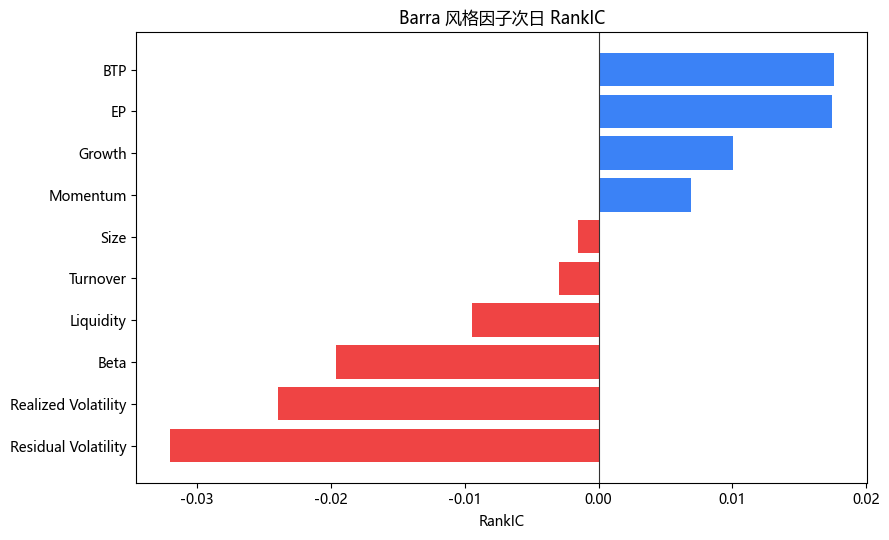

In [4]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(9,5.5))
colors = ['#ef4444' if x<0 else '#3b82f6' for x in bic['IC']]
ax.barh(bic.index, bic['IC'], color=colors)
ax.axvline(0, color='#333', lw=0.8)
ax.set_title('Barra 风格因子次日 RankIC'); ax.set_xlabel('RankIC')
plt.tight_layout(); plt.show()

## 五、因子相关性（暴露的截面相关）

In [5]:
valid = [n for n in bf if n != 'Leverage']
# 取每个因子的截面均值序列相关，反映因子风格的共动
mean_panel = pd.DataFrame({n: cross_zscore(bf[n]).mean(axis=1) for n in valid})
corr = mean_panel.corr()
print('因子相关矩阵（前6行）:')
print(corr.iloc[:6,:6].round(2).to_string())

因子相关矩阵（前6行）:
                     Size  Non-linear Size  Beta  Momentum  Residual Volatility  Realized Volatility
Size                 1.00              NaN  0.01      0.03                -0.06                 0.01
Non-linear Size       NaN              NaN   NaN       NaN                  NaN                  NaN
Beta                 0.01              NaN  1.00     -0.03                -0.02                -0.04
Momentum             0.03              NaN -0.03      1.00                -0.07                 0.00
Residual Volatility -0.06              NaN -0.02     -0.07                 1.00                -0.03
Realized Volatility  0.01              NaN -0.04      0.00                -0.03                 1.00


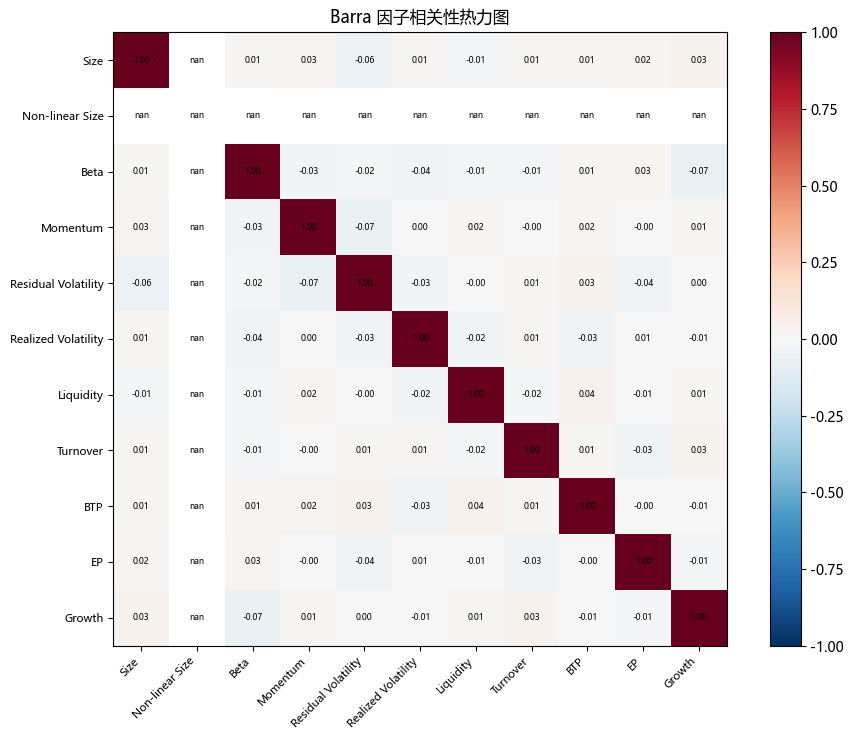

In [6]:
fig, ax = plt.subplots(figsize=(9.5,7.5))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns,
           rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j,i,'%.2f'%corr.values[i,j],ha='center',va='center',fontsize=6)
fig.colorbar(im, ax=ax, fraction=0.04)
ax.set_title('Barra 因子相关性热力图')
plt.tight_layout(); plt.show()

## 六、小结与面试要点

- Barra 用一组风格因子刻画个股，因子需标准化、去极值、检查共线性。
- 高相关因子（如两类波动）在风险模型里要处理，避免重复计风险。

**面试高频：**
- Barra 模型怎么构建？（答：因子暴露→截面回归因子收益→因子协方差+特异风险→重建协方差）
- 为什么要做 Non-linear Size？（答：市值与收益非线性，小盘内部分化大，立方项捕捉）
- Beta 怎么估计？（答：个股对基准滚动回归斜率，需窗口和对齐）
- 因子暴露为什么要标准化？（答：量纲不同，标准化后才能比较和回归）

## 动手练习
1. 构造全部 Barra 因子并比较 IC；
2. 找出相关性最高的因子对，思考风险模型如何处理；
3. 改变 Beta 窗口，观察 Beta 分布和稳定性。

---
下一节 M2.6 用这些因子构造纯因子组合。